# **Práctica sobre análisis de Fourier**

**Objetivos**

1. Analizar el comportamiento espectral de diferentes señales a partir del uso de herramientas de simulación como Python



# **Serie de Fourier**

Serie Compleja:

$$f(t) = \sum_{n=-∞}^{∞}{c_n e^{j2πnf_ot}}$$

$$c_n = \frac{1}{T_o}∫_{T_o}f(t)e^{-j2πnf_ot}dt $$

También existe la posibilidad de calcularla mediante los términos de la serie real:

$$f(t) = \frac{a_0}{2}+ \sum_{n=1}^{∞}a_ncos(nω_0t)+ \sum_{n=1}^{∞}b_nsin(nω_0t) $$

Coeficientes de la serie real:

$$a_0 = \frac{2}{T_0}∫_{T_0}f(t)dt, a_n=\frac{2}{T_0}∫_{T_0}f(t)cos(nω_0t)dt, b_n=\frac{2}{T_0}∫_{T_0}f(t)sin(nω_0t)dt$$

Relación entre coeficientes reales y complejos:

$$|c_n| = \sqrt{a_n^2 + b_n^2 }$$

Analice las funciones que se entregan a continuación, donde se calculan los N primeros coeficientes de la serie de Fourier para la señal de tren pulsado.

In [ ]:
from sympy import integrate, exp, symbols
import numpy as np
import matplotlib.pyplot as plt

def serie_fourier(Cn, N, T, f, fs, t):
    n_armonics = np.arange(-N,N+1,1)
    freq_spectrum = n_armonics*f
    #Compute n coeficients
    #Cn_eval = [np.fromiter([Cn.evalf(subs={n:i})], dtype=complex)[0]]

    f_t = 0
    Cn_eval = []
    for i in n_armonics:
        Cn_eval.append(np.abs(np.fromiter([Cn.evalf(subs={n:i})], dtype=complex)[0])) # "fromiter" convierte
        # los valores complejos simbólicos en complejos numéricos. Como genera lista, hay que evaluar el resultado
        # en la posición [0]
        armonic = np.fromiter([Cn.evalf(subs={n:i})], dtype=complex)*np.exp((1j*i*2*np.pi*f*t))
        f_t = f_t + armonic

    for i in n_armonics:
        if(i>=0):
           print("Freq = "+str((1/T)*i)+" Hz"+":"+" |c_"+str(i)+"| = "+str(Cn_eval[i+N]))

    plt.figure(figsize=(10,3))
    plt.subplot(121)
    plt.stem(freq_spectrum,np.asarray(Cn_eval)**2)
    plt.xlabel("Frecuencia [Hz]")
    plt.ylabel('Potencia [lineal]')
    plt.title("Espectro")

    plt.subplot(122)
    plt.plot(t,f_t)
    plt.xlabel("Tiempo (s)")
    plt.ylabel('Amplitud')
    plt.title("Serie de Fourier N = "+str(N)+" Terminos")
    plt.grid()
    plt.show()

n,t_simbol = symbols('n t_simbol')

Cn = (1/T)*integrate(A*exp(-(1j*W0*n*t_simbol)),
                     (t_simbol,0,Duty*T))

i = 0
Cn_eval = [np.fromiter([Cn.evalf(subs={n:i})], dtype=complex)[0]]

print("C_0 =", Cn_eval[0])
print("Potencia de C_0 =", abs(Cn_eval[0])**2)

Freq = 0.0 Hz: |c_0| = 0.5
Freq = 1000.0 Hz: |c_1| = 0.3183098861837907
Freq = 2000.0 Hz: |c_2| = 1.949085916259688e-17
Freq = 3000.0 Hz: |c_3| = 0.1061032953945969


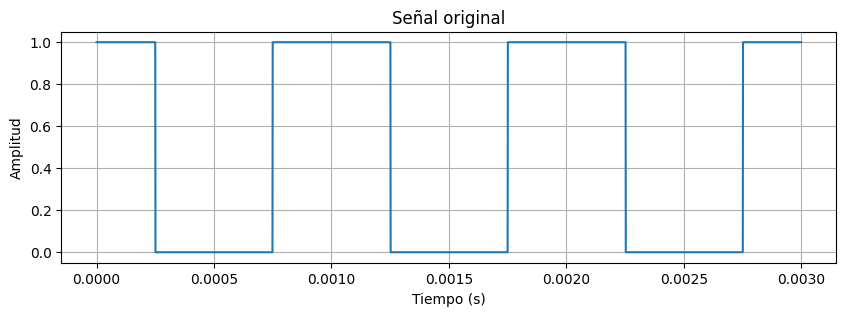

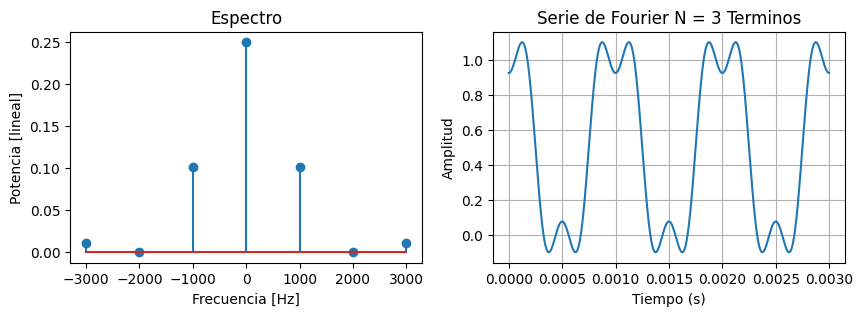

In [ ]:
f=1000
fs = 1e6 # fs para contruir el tren pulsado "continuo" en el computador
T=1/f
N_periods = 3
A=1
W0 = 2*np.pi*f # Frecuencia fundamental de la función

time_period = np.arange(0,T,1/fs) # Periodo de solo un pulso
ft_real_period = [A if 0 <= t <= T/4 or 3*T/4 <= t <= T else 0 for t in time_period]
time = np.arange(0,N_periods*T,1/fs)
#Graficar X cantidad de periodos de la señal
ft_real = np.hstack([ft_real_period for p in range(N_periods)])
plt.figure(figsize=(10,3))
plt.plot(time, ft_real[0:len(time)])
plt.xlabel("Tiempo (s)")
plt.ylabel('Amplitud')
plt.title("Señal original")
plt.grid()

n,t_simbol = symbols('n t_simbol')
N = 3 # N armónicos

Cn = (1/T)*integrate(A*exp(-(1j*W0*n*t_simbol)),(t_simbol,-T/4,T/4))

serie_fourier(Cn,N,T,f,fs, time)

In [ ]:
Cn

1000.0*Piecewise((-0.000159154943091895*I*exp(1.5707963267949*I*n)/n + 0.000159154943091895*I*exp(-1.5707963267949*I*n)/n, (n > -oo) & (n < oo) & Ne(n, 0)), (0.0005, True))

---
# **Laboratorio**
---

2. Considere una señal de tren pulsado con frecuencia $1000$ Hz y ciclo de dureza del $50\%$. Calcule:


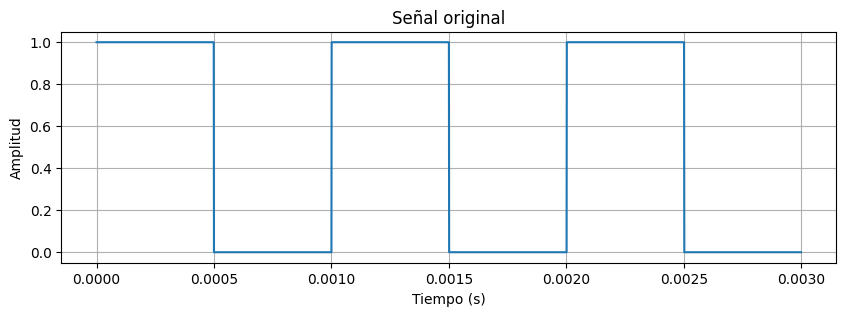

In [ ]:
f = 1000
fs = 1e6
T = 1/f
N_periods = 3
A = 1
Duty = 0.50
W0 = 2*np.pi*f

time_period = np.arange(0,T,1/fs)

ft_real_period = [A if t < Duty*T else 0 for t in time_period]

time = np.arange(0,N_periods*T,1/fs)

ft_real = np.hstack([ft_real_period for p in range(N_periods)])

plt.figure(figsize=(10,3))
plt.plot(time, ft_real[0:len(time)])
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.title("Señal original")
plt.grid()
plt.show()


Freq = 0.0 Hz: |c_0| = 0.5
Freq = 1000.0 Hz: |c_1| = 0.3183098861837907
Freq = 2000.0 Hz: |c_2| = 1.949085916259688e-17
Freq = 3000.0 Hz: |c_3| = 0.1061032953945969
Freq = 4000.0 Hz: |c_4| = 1.949085916259688e-17
Freq = 5000.0 Hz: |c_5| = 0.06366197723675815
Freq = 6000.0 Hz: |c_6| = 1.9490859162596877e-17
Freq = 7000.0 Hz: |c_7| = 0.04547284088339867
Freq = 8000.0 Hz: |c_8| = 1.949085916259688e-17
Freq = 9000.0 Hz: |c_9| = 0.0353677651315323
Freq = 10000.0 Hz: |c_10| = 1.949085916259688e-17


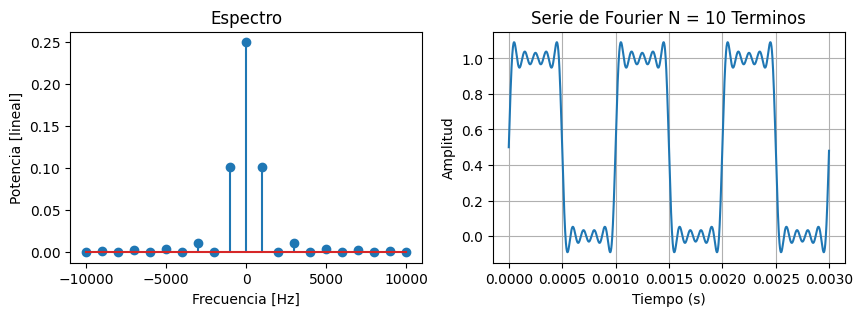

In [ ]:
n,t_simbol = symbols('n t_simbol')
N = 10

Cn = (1/T)*integrate(A*exp(-(1j*W0*n*t_simbol)),
                     (t_simbol,0,Duty*T))

serie_fourier(Cn,N,T,f,fs,time)

In [ ]:
Cn

1000.0*Piecewise((-0.000159154943091895*I/n + 0.000159154943091895*I*exp(-3.14159265358979*I*n)/n, (n > -oo) & (n < oo) & Ne(n, 0)), (0.0005, True))

* La potencia de la señal

In [ ]:
# Potencia de la señal
P_total = A**2*Duty

print("Potencia de la señal:", P_total)


Potencia de la señal: 0.5


* La potencia de cada armónico

In [ ]:
# Potencia de cada armónico
n_valores = np.arange(0,11)
potencias = []

for i in n_valores:
    Cn_i = complex(Cn.evalf(subs={n:i}))
    Pn = abs(Cn_i)**2
    potencias.append(Pn)
    print("Armónico", i, "- Frecuencia:", i*f,
          "Hz - Potencia:", Pn)

# Potencia considerando frecuencias positivas y negativas
P_calculada = potencias[0] + 2*sum(potencias[1:])

print("Potencia aproximada con 10 armónicos:", P_calculada)

Armónico 0 - Frecuencia: 0 Hz - Potencia: 0.25
Armónico 1 - Frecuencia: 1000 Hz - Potencia: 0.10132118364233779
Armónico 2 - Frecuencia: 2000 Hz - Potencia: 3.798935908961868e-34
Armónico 3 - Frecuencia: 3000 Hz - Potencia: 0.011257909293593087
Armónico 4 - Frecuencia: 4000 Hz - Potencia: 3.798935908961868e-34
Armónico 5 - Frecuencia: 5000 Hz - Potencia: 0.004052847345693513
Armónico 6 - Frecuencia: 6000 Hz - Potencia: 3.7989359089618666e-34
Armónico 7 - Frecuencia: 7000 Hz - Potencia: 0.0020677792580068933
Armónico 8 - Frecuencia: 8000 Hz - Potencia: 3.798935908961868e-34
Armónico 9 - Frecuencia: 9000 Hz - Potencia: 0.001250878810399232
Armónico 10 - Frecuencia: 10000 Hz - Potencia: 3.798935908961868e-34
Potencia aproximada con 10 armónicos: 0.48990119670006105


* El número de componentes necesarios para alcanzar el 90% de la potencia

In [ ]:
# Número de componentes para alcanzar el 90% de la potencia
P_objetivo = 0.9 * P_total
P_acumulada = potencias[0]
N_componentes = 1  # Componente de continua (n=0)

for i in range(1, len(potencias)):
    P_acumulada += 2 * potencias[i]
    N_componentes += 2  # Frecuencias positiva y negativa
    if P_acumulada >= P_objetivo:
        break

print("90% de la potencia:", P_objetivo)
print("Número de componentes necesarios:", N_componentes)
print("Potencia alcanzada:", P_acumulada)

90% de la potencia: 0.45
Número de componentes necesarios: 3
Potencia alcanzada: 0.45264236728467555


* El ancho de banda

In [ ]:
# Ancho de banda hasta el primer cero de la envolvente
B_referencia = f/Duty

print("Frecuencia fundamental:", f, "Hz")
print("Ciclo de trabajo:", Duty*100, "%")
print("Ancho de banda hasta el primer cero:",
      B_referencia, "Hz")


Frecuencia fundamental: 1000 Hz
Ciclo de trabajo: 50.0 %
Ancho de banda hasta el primer cero: 2000.0 Hz


* Modifice los parámetros de frecuencia y ciclo de dureza de la señal (Freq: 500Hz y 20000Hz; Duty: 25% y 75%. Las cuatro combinaciones) y concluya lo que se observa en el espectro resultante.

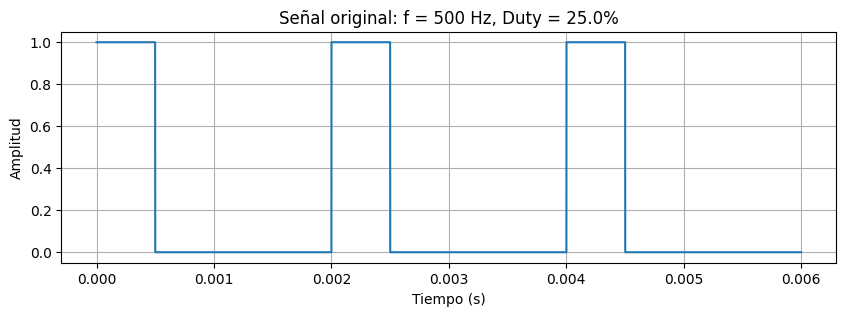

Frecuencia: 500 Hz
Ciclo de trabajo: 25.0 %
Freq = 0.0 Hz: |c_0| = 0.25
Freq = 500.0 Hz: |c_1| = 0.22507907903927654
Freq = 1000.0 Hz: |c_2| = 0.15915494309189535
Freq = 1500.0 Hz: |c_3| = 0.07502635967975885
Freq = 2000.0 Hz: |c_4| = 9.74542958129844e-18
Freq = 2500.0 Hz: |c_5| = 0.04501581580785531
Freq = 3000.0 Hz: |c_6| = 0.05305164769729845
Freq = 3500.0 Hz: |c_7| = 0.03215415414846808
Freq = 4000.0 Hz: |c_8| = 9.74542958129844e-18
Freq = 4500.0 Hz: |c_9| = 0.02500878655991961
Freq = 5000.0 Hz: |c_10| = 0.031830988618379075


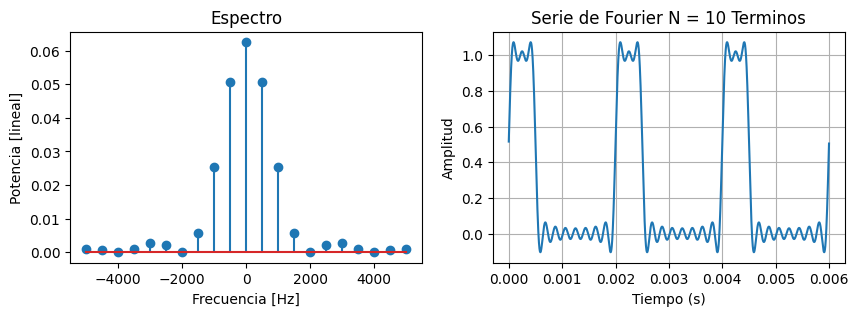

Potencia de la señal: 0.25
Ancho de banda teórico: infinito
Primer cero de la envolvente: 2000.0 Hz
---------------------------------------


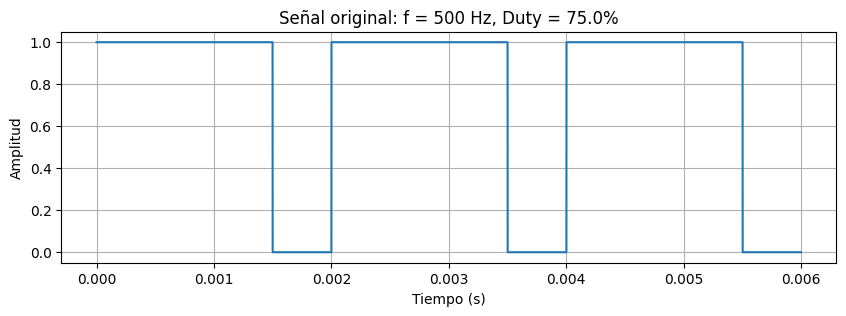

Frecuencia: 500 Hz
Ciclo de trabajo: 75.0 %
Freq = 0.0 Hz: |c_0| = 0.75
Freq = 500.0 Hz: |c_1| = 0.22507907903927654
Freq = 1000.0 Hz: |c_2| = 0.15915494309189535
Freq = 1500.0 Hz: |c_3| = 0.07502635967975882
Freq = 2000.0 Hz: |c_4| = 2.923628874389532e-17
Freq = 2500.0 Hz: |c_5| = 0.045015815807855374
Freq = 3000.0 Hz: |c_6| = 0.05305164769729845
Freq = 3500.0 Hz: |c_7| = 0.03215415414846808
Freq = 4000.0 Hz: |c_8| = 2.923628874389532e-17
Freq = 4500.0 Hz: |c_9| = 0.025008786559919657
Freq = 5000.0 Hz: |c_10| = 0.031830988618379075


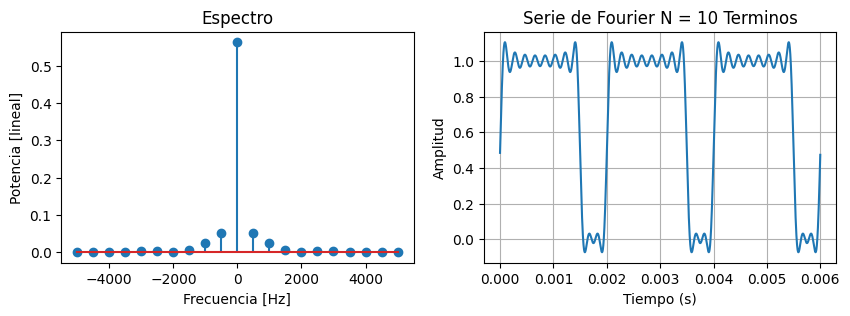

Potencia de la señal: 0.75
Ancho de banda teórico: infinito
Primer cero de la envolvente: 2000.0 Hz
---------------------------------------


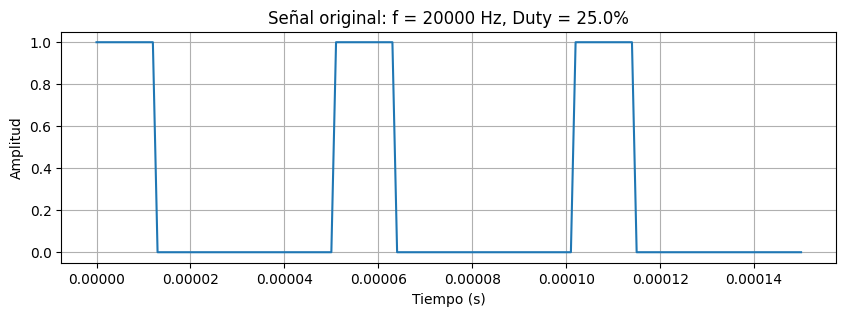

Frecuencia: 20000 Hz
Ciclo de trabajo: 25.0 %
Freq = 0.0 Hz: |c_0| = 0.25
Freq = 20000.0 Hz: |c_1| = 0.22507907903927654
Freq = 40000.0 Hz: |c_2| = 0.15915494309189535
Freq = 60000.0 Hz: |c_3| = 0.0750263596797588
Freq = 80000.0 Hz: |c_4| = 2.5594066879407303e-17
Freq = 100000.0 Hz: |c_5| = 0.04501581580785532
Freq = 120000.0 Hz: |c_6| = 0.05305164769729844
Freq = 140000.0 Hz: |c_7| = 0.03215415414846805
Freq = 160000.0 Hz: |c_8| = 2.5594066879407303e-17
Freq = 180000.0 Hz: |c_9| = 0.025008786559919626
Freq = 200000.0 Hz: |c_10| = 0.03183098861837907


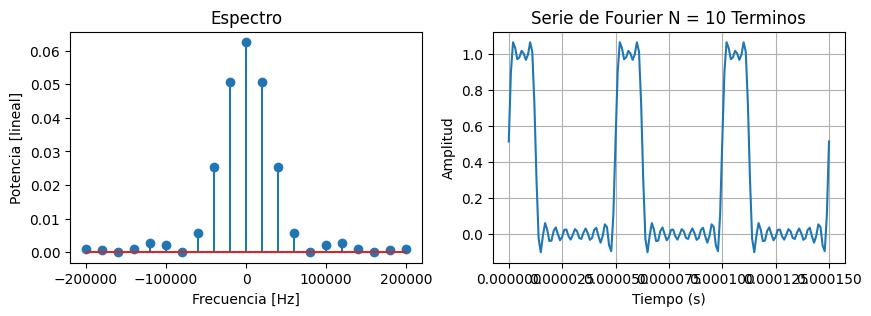

Potencia de la señal: 0.25
Ancho de banda teórico: infinito
Primer cero de la envolvente: 80000.0 Hz
---------------------------------------


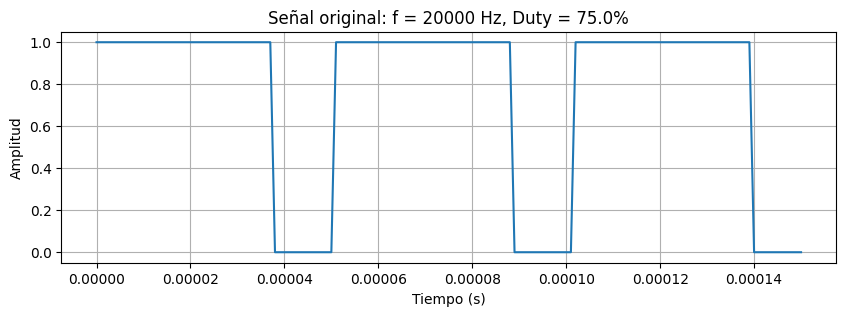

Frecuencia: 20000 Hz
Ciclo de trabajo: 75.0 %
Freq = 0.0 Hz: |c_0| = 0.7500000000000001
Freq = 20000.0 Hz: |c_1| = 0.22507907903927643
Freq = 40000.0 Hz: |c_2| = 0.15915494309189535
Freq = 60000.0 Hz: |c_3| = 0.07502635967975887
Freq = 80000.0 Hz: |c_4| = 1.1212169709892766e-16
Freq = 100000.0 Hz: |c_5| = 0.04501581580785521
Freq = 120000.0 Hz: |c_6| = 0.05305164769729844
Freq = 140000.0 Hz: |c_7| = 0.03215415414846819
Freq = 160000.0 Hz: |c_8| = 1.1212169709892766e-16
Freq = 180000.0 Hz: |c_9| = 0.025008786559919567
Freq = 200000.0 Hz: |c_10| = 0.03183098861837907


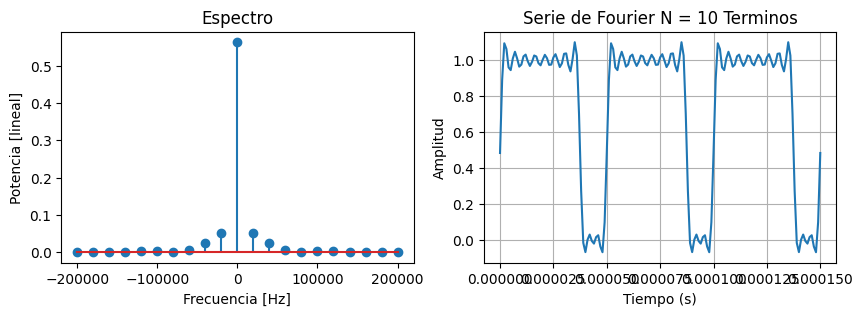

Potencia de la señal: 0.75
Ancho de banda teórico: infinito
Primer cero de la envolvente: 80000.0 Hz
---------------------------------------


In [ ]:
frecuencias = [500, 20000]
#duties = [0.25, 0.75,0.9]
duties = [0.25, 0.75]
N = 10
for f in frecuencias:
    for Duty in duties:

        T = 1/f
        W0 = 2*np.pi*f

        time_period = np.arange(0,T,1/fs)
        ft_real_period = [A if t < Duty*T else 0 for t in time_period]

        time = np.arange(0,N_periods*T,1/fs)
        ft_real = np.hstack([ft_real_period for p in range(N_periods)])

        plt.figure(figsize=(10,3))
        plt.plot(time,ft_real[0:len(time)])
        plt.xlabel("Tiempo (s)")
        plt.ylabel("Amplitud")
        plt.title("Señal original: f = "+str(f)+" Hz, Duty = "+str(Duty*100)+"%")
        plt.grid()
        plt.show()

        Cn = (1/T)*integrate(A*exp(-(1j*W0*n*t_simbol)),
                             (t_simbol,0,Duty*T))

        print("Frecuencia:",f,"Hz")
        print("Ciclo de trabajo:",Duty*100,"%")

        serie_fourier(Cn,N,T,f,fs,time)

        P_total = A**2*Duty
        # Calcular correctamente el primer cero de la envolvente
        if Duty <= 0.5:
            B_referencia = f / Duty
        else:
            B_referencia = f / (1 - Duty)
        #B_referencia = f/Duty

        print("Potencia de la señal:",P_total)
        print("Ancho de banda teórico: infinito")
        print("Primer cero de la envolvente:",B_referencia,"Hz")
        print("---------------------------------------")



Efecto de la frecuencia: al aumentar la frecuencia fundamental de 500 Hz a 20 000 Hz, las componentes del espectro se desplazan hacia frecuencias más altas. La separación entre armónicos también aumenta, pues coincide con la frecuencia fundamental.

Efecto del ciclo de trabajo: al modificar el ciclo de trabajo, cambia la forma del espectro y la posición de sus ceros. Un ciclo de trabajo del 25 % produce una señal más estrecha en el tiempo que uno del 75 %, aunque ambos tienen la misma duración de período para una frecuencia dada.

Ancho de banda: una señal rectangular ideal tiene ancho de banda infinito, porque contiene infinitos armónicos. Sin embargo, el primer cero de la envolvente permite comparar de manera práctica la distribución espectral de las cuatro señales.

## **Construcción de un Espectrograma**

1. Usando una frecuencia de muestreo $f_s=512$ [muestras/segundo], genere las señales cosenonoidales $s_1$, $s_2$, $s_3$ y $s_4$ con frecuencias $16$ Hz, $32$ Hz, $64$ Hz y $128$ Hz, respectivamente, y $250$ ms de duración. Construya la señal $s$ concatenando horizontalmente las 4 señales. Realice el gráfico de la señal $s$ en el tiempo  

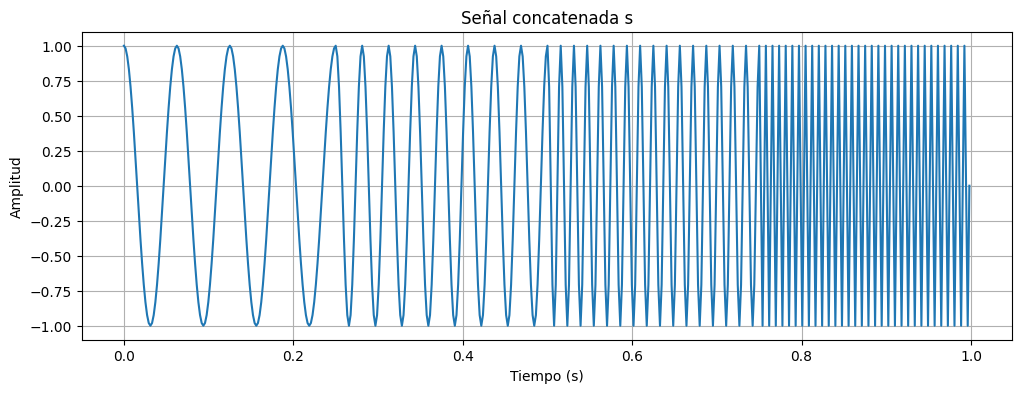

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fs = 512  # Frecuencia de muestreo [muestras/segundo]
duracion = 0.250  # Duración de cada señal en segundos
A = 1  # Amplitud

t = np.arange(0, duracion, 1/fs)

# Generar las señales cosenoidales
s1 = A*np.cos(2*np.pi*16*t)
s2 = A*np.cos(2*np.pi*32*t)
s3 = A*np.cos(2*np.pi*64*t)
s4 = A*np.cos(2*np.pi*128*t)

# Concatenar horizontalmente las cuatro señales
s = np.hstack([s1, s2, s3, s4])

# Vector de tiempo para la señal concatenada
time = np.arange(0, len(s)/fs, 1/fs)

# Graficar la señal completa
plt.figure(figsize=(12,4))
plt.plot(time, s)
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.title("Señal concatenada s")
plt.grid()
plt.show()


2. Utilice la función `np.fft.fft(señal)` para calcular la Transformada Discreta de Fourier (en Inglés, DFT) (usando el algorítmo Fast Fourier Transform, FFT) de las señales $s_1$, $s_2$, $s_3$ y $s_4$. Grafique las 4 transformadas en la misma figura tal que el eje vertical es la frecuencia y el eje horizontal es la magnitud.

    **Nota**: Solamente incluya las frecuencias positivas en el gráfico y normalice las transformadas de modo que solamente tome valores entre $0$ y $1$

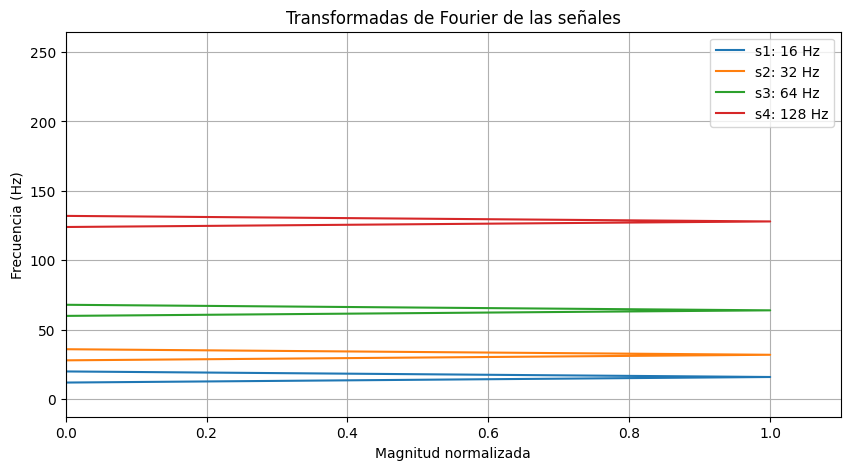

In [ ]:
# Calcular la FFT de las cuatro señales
S1 = np.fft.fft(s1)
S2 = np.fft.fft(s2)
S3 = np.fft.fft(s3)
S4 = np.fft.fft(s4)

# Calcular las magnitudes y normalizarlas
S1_mag = np.abs(S1)/max(np.abs(S1))
S2_mag = np.abs(S2)/max(np.abs(S2))
S3_mag = np.abs(S3)/max(np.abs(S3))
S4_mag = np.abs(S4)/max(np.abs(S4))

# Vector de frecuencias positivas
frecuencias = np.fft.fftfreq(len(s1), 1/fs)
pos = frecuencias >= 0

# Graficar las cuatro transformadas
plt.figure(figsize=(10,5))

plt.plot(S1_mag[pos], frecuencias[pos], label="s1: 16 Hz")
plt.plot(S2_mag[pos], frecuencias[pos], label="s2: 32 Hz")
plt.plot(S3_mag[pos], frecuencias[pos], label="s3: 64 Hz")
plt.plot(S4_mag[pos], frecuencias[pos], label="s4: 128 Hz")

plt.xlabel("Magnitud normalizada")
plt.ylabel("Frecuencia (Hz)")
plt.title("Transformadas de Fourier de las señales")
plt.xlim(0,1.1)
plt.legend()
plt.grid()
plt.show()

print(S1_mag[pos])
plt.figure(figsize=(8, 5))
plt.stem(S1_mag[pos], frecuencias[pos])
plt.xlabel("Magnitud normalizada")
plt.ylabel("Frecuencia (Hz)")
plt.title("Espectro de magnitud de s1")
plt.grid()
plt.show()

### Conclusión

- Las señales cosenoidales tienen su componente espectral en la frecuencia correspondiente.
- La FFT calcula valores en frecuencias discretas, determinadas por la duración de la señal y la frecuencia de muestreo.
- La normalización hace que el máximo de cada espectro tenga una magnitud igual a 1.
- Las dos rayas inclinadas que se observan alrededor de cada pico se deben a la representación con `plt.plot()`, que conecta los puntos vecinos. Por lo tanto, no significan que la señal tenga dos frecuencias positivas distintas.

En este caso, cada señal tiene una duración de 0.25 s, por lo que la separación entre los bins de frecuencia es:

$$
\Delta f = \frac{1}{0.25} = 4\text{ Hz}
$$

3. La función `plt.imshow(matriz)` permite representar una matriz como una imagen donde el color de cada pixel está dado por el valor correspondiente en la matriz. Realice un subplot de 1x4. En cada eje utilice la función `plt.imshow(matriz)` para representar gráficamente la DFT de las señales $s_i$. Superponga en cada imagen, la DFT correspondiente como una función de frecuencia (graficada en el punto anterior)

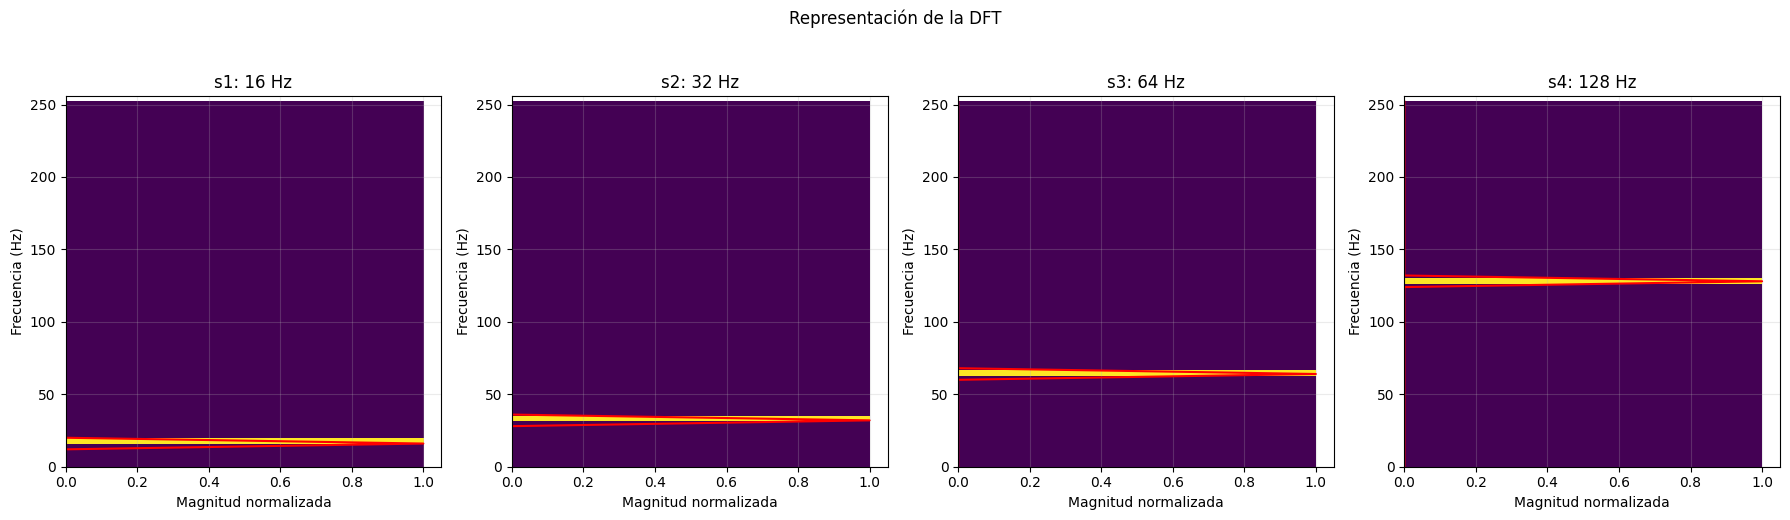

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Señales generadas anteriormente
senales = [s1, s2, s3, s4]
titulos = ["s1: 16 Hz", "s2: 32 Hz", "s3: 64 Hz", "s4: 128 Hz"]

# Crear un subplot de 1 fila y 4 columnas
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for i, ax in enumerate(axes):

    senal = senales[i]
    L = len(senal)

    # 1. Calcular la DFT usando FFT
    espectro = np.fft.fft(senal)

    # 2. Obtener las frecuencias correspondientes
    frecuencias = np.fft.fftfreq(L, d=1/fs)

    # 3. Conservar las frecuencias no negativas
    indices = frecuencias >= 0
    frecuencias_pos = frecuencias[indices]
    magnitud = np.abs(espectro[indices])

    # Normalizar la magnitud para facilitar la comparación
    magnitud = magnitud / np.max(magnitud)

    # 4. Crear una matriz 2D para representar el espectro con imshow
    matriz = np.tile(magnitud[:, np.newaxis], (1, 30))

    ax.imshow(
        matriz,
        aspect="auto",
        origin="lower",
        extent=[0, 1, frecuencias_pos[0], frecuencias_pos[-1]],
        cmap="viridis"
    )

    # 5. Superponer la DFT como función de frecuencia
    ax.plot(
        magnitud,
        frecuencias_pos,
        color="red",
        linewidth=1.5
    )

    ax.set_title(titulos[i])
    ax.set_xlabel("Magnitud normalizada")
    ax.set_ylabel("Frecuencia (Hz)")
    ax.set_xlim(0, 1.05)
    ax.set_ylim(0, fs/2)
    ax.grid(alpha=0.25)

plt.suptitle("Representación de la DFT", y=1.03)
plt.tight_layout()
plt.show()


4. El siguiente código ulitiza la función `plt.specgram` para graficar el espectrograma de una señal dada $s$.

* ¿Qué pasa si se elige NFFT $=128; 64; 100$? concluya.

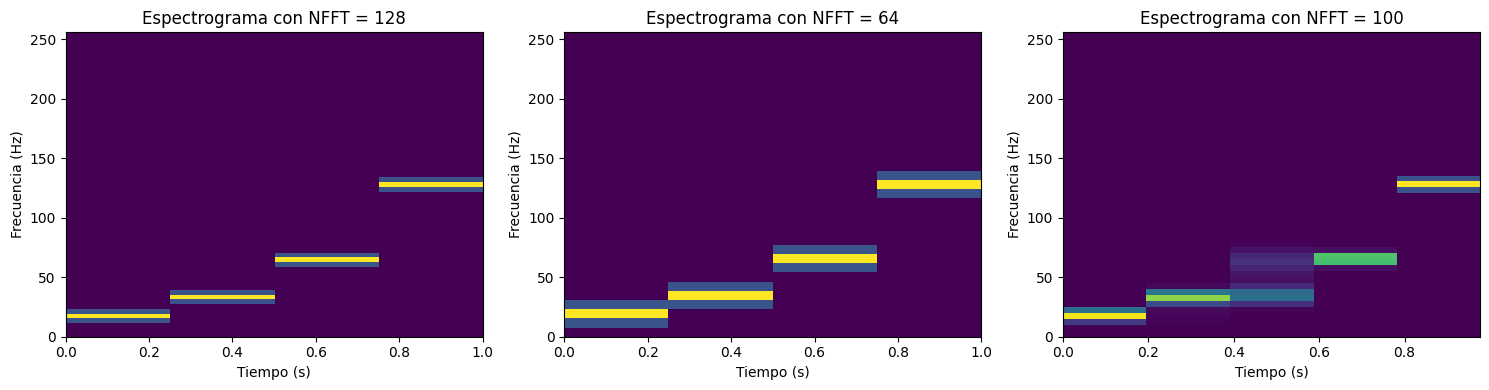

In [ ]:
# Espectrogramas con diferentes valores de NFFT
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# Espectrograma con NFFT = 128
ax[0].specgram(s, Fs=fs, NFFT=128, noverlap=0,
               cmap='viridis', scale='linear')
ax[0].set_title('Espectrograma con NFFT = 128')
ax[0].set_xlabel('Tiempo (s)')
ax[0].set_ylabel('Frecuencia (Hz)')

# Espectrograma con NFFT = 64
ax[1].specgram(s, Fs=fs, NFFT=64, noverlap=0,
               cmap='viridis', scale='linear')
ax[1].set_title('Espectrograma con NFFT = 64')
ax[1].set_xlabel('Tiempo (s)')
ax[1].set_ylabel('Frecuencia (Hz)')

# Espectrograma con NFFT = 100
ax[2].specgram(s, Fs=fs, NFFT=100, noverlap=0,
               cmap='viridis', scale='linear')
ax[2].set_title('Espectrograma con NFFT = 100')
ax[2].set_xlabel('Tiempo (s)')
ax[2].set_ylabel('Frecuencia (Hz)')

plt.tight_layout()
plt.show()

## 1. ¿Qué pasa si se elige NFFT = 128, 64 y 100?

El parámetro `NFFT` determina el número de muestras utilizadas en cada segmento

Una aclaración importante: NFFT no cambia la señal original ni hace que el sonido dure más o menos; cambia cómo se analiza y representa su contenido frecuencial a lo largo del tiempo.

resolución frecuencial se calcula aproximadamente mediante:

$$
\Delta f=\frac{f_s}{NFFT}
$$

Considerando una frecuencia de muestreo de $f_s=512$ muestras/s, se obtienen los siguientes resultados:

- **NFFT = 128:** la resolución frecuencial es de $4\,\text{Hz}$. Permite distinguir mejor las frecuencias cercanas, pero ofrece menor resolución temporal.
- **NFFT = 64:** la resolución frecuencial es de $8\,\text{Hz}$. Proporciona mayor resolución temporal, pero menor capacidad para distinguir frecuencias próximas.
- **NFFT = 100:** la resolución frecuencial es de $5.12\,\text{Hz}$. Presenta un comportamiento intermedio entre los dos casos anteriores.

**Conclusión:** al aumentar el valor de `NFFT`, mejora la resolución frecuencial, pero disminuye la resolución temporal. Por el contrario, al reducirlo, se obtiene una mejor localización temporal, aunque se pierde precisión para distinguir frecuencias cercanas.


* ¿Qué significa que el parámetro `noverlap` sea cero? utilice un valor diferente y concluya.

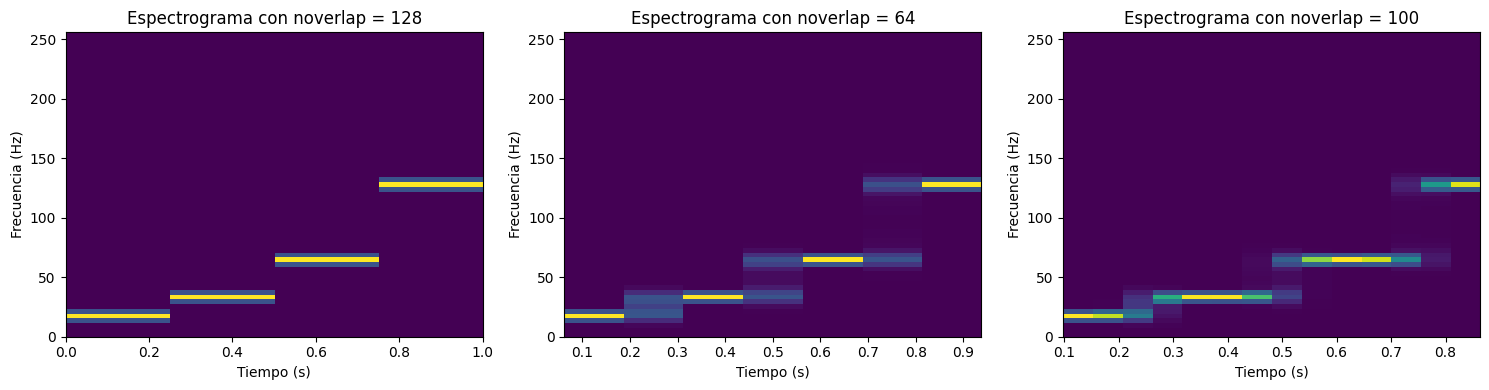

In [ ]:
# Espectrogramas con diferentes valores de NFFT
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# Espectrograma con noverlap = 0
ax[0].specgram(s, Fs=fs, NFFT=128, noverlap=0,
               cmap='viridis', scale='linear')
ax[0].set_title('Espectrograma con noverlap = 128')
ax[0].set_xlabel('Tiempo (s)')
ax[0].set_ylabel('Frecuencia (Hz)')

# Espectrograma con noverlap = 64
ax[1].specgram(s, Fs=fs, NFFT=128, noverlap=64,
               cmap='viridis', scale='linear')
ax[1].set_title('Espectrograma con noverlap = 64')
ax[1].set_xlabel('Tiempo (s)')
ax[1].set_ylabel('Frecuencia (Hz)')

# Espectrograma con noverlap = 100
ax[2].specgram(s, Fs=fs, NFFT=128, noverlap=100,
               cmap='viridis', scale='linear')
ax[2].set_title('Espectrograma con noverlap = 100')
ax[2].set_xlabel('Tiempo (s)')
ax[2].set_ylabel('Frecuencia (Hz)')

plt.tight_layout()

* ¿Por qué `noverlap` no puede ser mayor que NFFT?

El parámetro `noverlap` indica el número de muestras compartidas entre dos segmentos consecutivos al calcular el espectrograma.

Cuando `noverlap = 0`, los segmentos no comparten muestras y cada uno comienza después de que termina el anterior. Esto permite analizar la señal por bloques independientes.

Por ejemplo, si se utiliza `NFFT = 128` y `noverlap = 64`, los segmentos consecutivos comparten 64 muestras, equivalentes al 50 % del tamaño de la ventana.

**Conclusión:** al utilizar un solapamiento del 50 %, se obtiene una representación temporal más continua y se calculan más segmentos que cuando no existe solapamiento. Esto puede facilitar la observación de los cambios de la señal, aunque aumenta el costo computacional. El solapamiento no mejora por sí mismo la resolución frecuencial de cada segmento.

## 3. ¿Por qué noverlap no puede ser mayor que NFFT?

El parámetro `NFFT` define el número de muestras de cada segmento, mientras que `noverlap` indica cuántas muestras se comparten con el siguiente segmento.

Por esta razón, el número de muestras solapadas debe ser menor que el tamaño de la ventana. Por ejemplo, si `NFFT = 128`, se pueden utilizar valores de `noverlap` entre 0 y 127.

Si `noverlap` es igual o superior a `NFFT`, se produce un error, ya que no existe un desplazamiento positivo válido entre segmentos consecutivos.

**Conclusión:** el solapamiento debe cumplir la condición

$$
0\leq \text{noverlap}<NFFT
$$

Esto garantiza que cada segmento avance respecto al anterior y que el espectrograma pueda calcularse correctamente.

## **Construcción de un Espectrograma 2**
Señal de audio.

1. Cargue la señal de audio `senal.wav`. Seleccione el segmento entre $18.75$ ms y $318.75$ ms ($300$ ms de duración). Reproduzca la señal y grafiquela en el tiempo y en frecuencia mediante su espectrograma usando la función `plt.spectrogram()`.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio, display

# 1. Cargar el archivo de audio
fs, senal = wavfile.read('senal.wav')

# Reproducir el audio
display(Audio(senal, rate=fs))

Frecuencia de muestreo: 16000 Hz
Duración del segmento: 300.00 ms


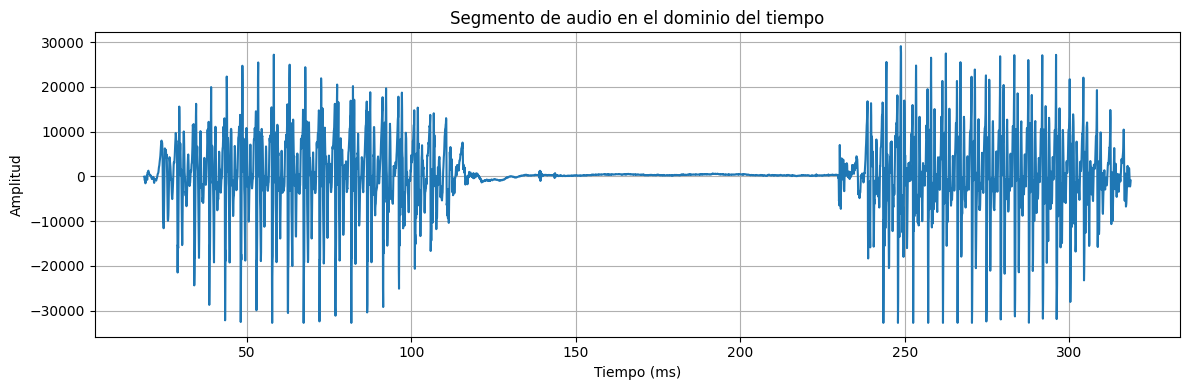

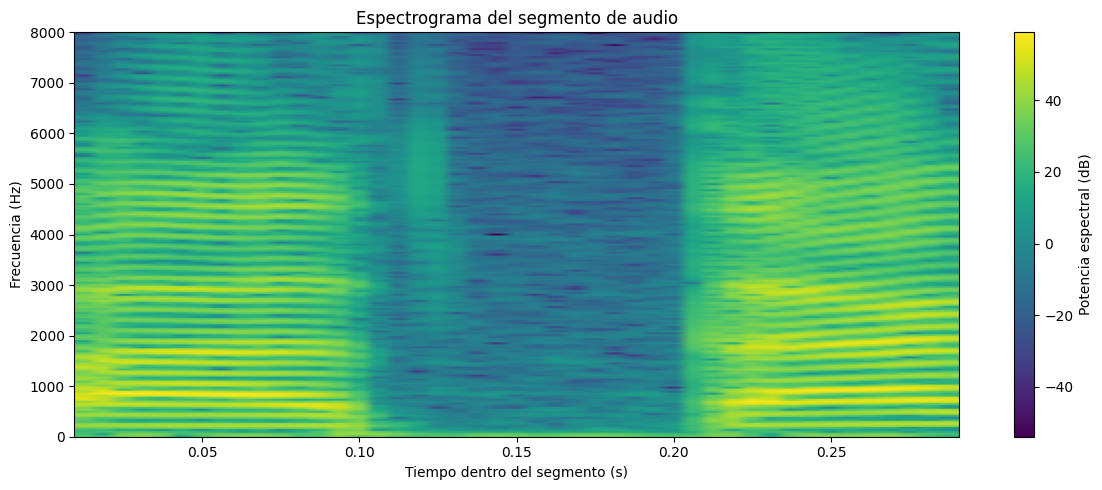

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio, display

# 1. Cargar el archivo de audio
fs, senal = wavfile.read('senal.wav')

# Si el audio es estéreo, convertirlo a mono
if senal.ndim == 2:
    senal = senal.mean(axis=1)

# Convertir a punto flotante para facilitar el procesamiento
senal = senal.astype(float)

# Normalizar si es necesario para reproducirlo cómodamente
if np.max(np.abs(senal)) > 0:
    audio_normalizado = senal / np.max(np.abs(senal))
else:
    audio_normalizado = senal

# 2. Extraer el segmento entre 18.75 ms y 318.75 ms
t_inicio = 18.75e-3
t_final = 318.75e-3

muestra_inicio = int(round(t_inicio * fs))
muestra_final = int(round(t_final * fs))

segmento = senal[muestra_inicio:muestra_final]
segmento_audio = audio_normalizado[muestra_inicio:muestra_final]

# Vector de tiempo del segmento, en segundos
tiempo = np.arange(len(segmento)) / fs + t_inicio

print(f"Frecuencia de muestreo: {fs} Hz")
print(f"Duración del segmento: {len(segmento)/fs*1000:.2f} ms")

# 3. Reproducir el segmento de audio
display(Audio(segmento_audio, rate=fs))

# 4. Graficar la señal en el tiempo
plt.figure(figsize=(12, 4))
plt.plot(tiempo * 1000, segmento)
plt.xlabel('Tiempo (ms)')
plt.ylabel('Amplitud')
plt.title('Segmento de audio en el dominio del tiempo')
plt.grid()
plt.tight_layout()
plt.show()

# 5. Graficar el espectrograma
plt.figure(figsize=(12, 5))

plt.specgram(
    segmento,
    Fs=fs,
    #NFFT=1024,
    #noverlap=768,
    NFFT=400,
    noverlap=300,
    cmap='viridis',
    scale='dB'
)

plt.xlabel('Tiempo dentro del segmento (s)')
plt.ylabel('Frecuencia (Hz)')
plt.title('Espectrograma del segmento de audio')
plt.colorbar(label='Potencia espectral (dB)')
plt.tight_layout()
plt.show()


2. Divida la señal anterior en tres segmentos de $100$ ms cada uno y realice una aproximación al espectrograma usando la DFT de cada segmento del mismo modo que se realizó en el punto 2 de la sección "Construcción de un Espectrograma", donde se construyó "a mano" el concepto de espectrograma usando la función `plt.imshow`.

    * Dibuje el espectro de cada ventana sobre cada ventana (por ejemplo usando color rojo) de los espectrogramas calculados en el ítem anterior.

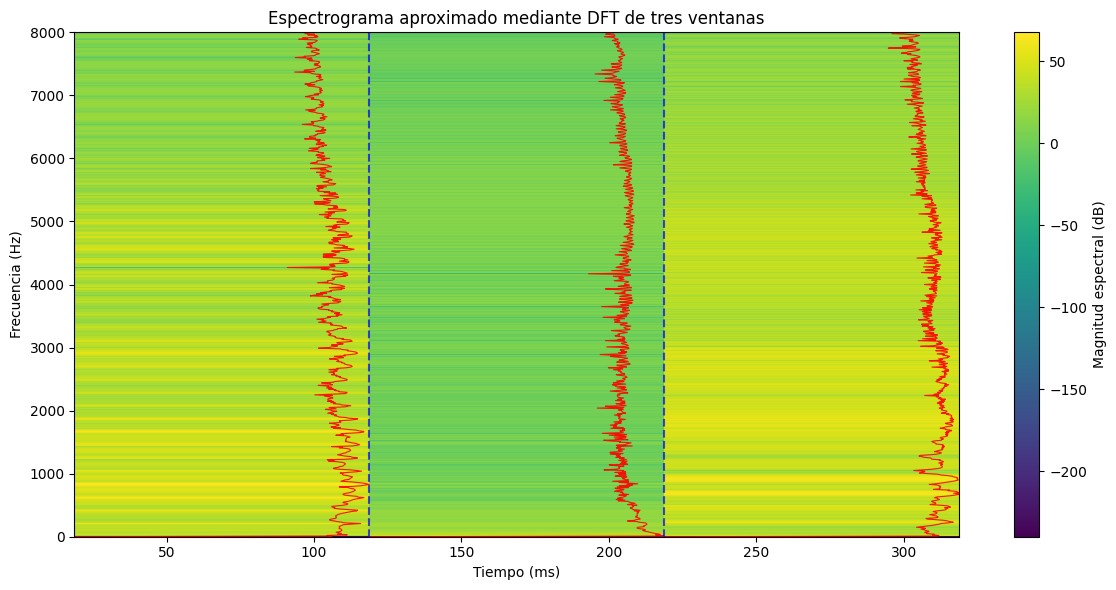

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Dividir el segmento de audio en tres ventanas de 100 ms
duracion_ventana = 0.100
muestras_ventana = int(round(duracion_ventana * fs))

ventanas = [
    segmento[i * muestras_ventana:(i + 1) * muestras_ventana]
    for i in range(3)
]

# 2. Calcular la DFT de cada ventana
espectros = []

for ventana in ventanas:
    # Eliminar la componente DC
    ventana = ventana - np.mean(ventana)

    # DFT calculada mediante FFT
    X = np.fft.fft(ventana)

    # Conservar las frecuencias no negativas
    X_positivo = X[:muestras_ventana // 2 + 1]

    # Magnitud y conversión a dB
    magnitud = np.abs(X_positivo) / len(ventana)
    espectro_db = 20 * np.log10(magnitud + 1e-12)

    espectros.append(espectro_db)

# Matriz: filas = frecuencias, columnas = ventanas
espectros = np.array(espectros).T

# Vector de frecuencias positivas
frecuencias = np.fft.rfftfreq(muestras_ventana, d=1/fs)

# 3. Construir el espectrograma aproximado con imshow
tiempo_inicio_ms = t_inicio * 1000
tiempo_final_ms = tiempo_inicio_ms + 300

plt.figure(figsize=(12, 6))

plt.imshow(
    espectros,
    origin='lower',
    aspect='auto',
    extent=[
        tiempo_inicio_ms,
        tiempo_final_ms,
        frecuencias[0],
        frecuencias[-1]
    ],
    cmap='viridis',
    interpolation='nearest'
)

plt.colorbar(label='Magnitud espectral (dB)')
plt.xlabel('Tiempo (ms)')
plt.ylabel('Frecuencia (Hz)')
plt.title('Espectrograma aproximado mediante DFT de tres ventanas')

# 4. Superponer el espectro de cada ventana en rojo
for i in range(3):
    t0 = tiempo_inicio_ms + i * 100
    t1 = t0 + 100

    espectro_db = espectros[:, i]

    # Normalizar para visualizar el espectro dentro de cada ventana
    magnitud_norm = espectro_db - np.min(espectro_db)
    maximo = np.max(magnitud_norm)

    if maximo > 0:
        magnitud_norm = magnitud_norm / maximo

    tiempo_espectro = t0 + magnitud_norm * (t1 - t0)

    plt.plot(
        tiempo_espectro,
        frecuencias,
        color='red',
        linewidth=0.8,
        alpha=0.9
    )

    if i > 0:
        plt.axvline(t0, color='blue', linestyle='--', alpha=0.7)

plt.ylim(0, fs / 2)
plt.tight_layout()
plt.show()


## **5. Graficar individualmente el espectro de cada ventana**

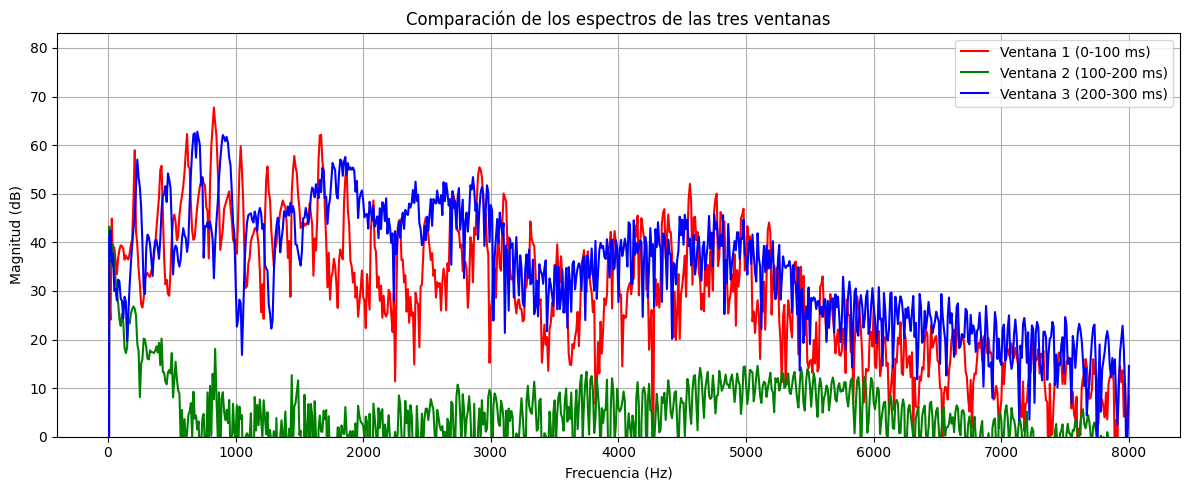

In [ ]:
# 5. Graficar los tres espectros en un solo plot
plt.figure(figsize=(12, 5))

colores = ['red', 'green', 'blue']

for i in range(3):
    plt.plot(
        frecuencias,
        espectros[:, i],
        color=colores[i],
        label=f'Ventana {i+1} ({i*100}-{(i+1)*100} ms)'
    )

plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Magnitud (dB)')
plt.title('Comparación de los espectros de las tres ventanas')
plt.ylim(bottom=0)# El eje vertical comienza en 0
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# 5. Graficar individualmente el espectro de cada ventana
fig, axes = plt.subplots(3, 1, figsize=(10, 9))

for i, ax in enumerate(axes):
    ax.plot(frecuencias, espectros[:, i], color='red')
    ax.set_title(
        f'Espectro de la ventana {i+1} '
        f'({i*100}-{(i+1)*100} ms)'
    )
    ax.set_xlabel('Frecuencia (Hz)')
    ax.set_ylabel('Magnitud (dB)')
    ax.set_ylim(bottom=0)  # El eje vertical comienza en 0
    ax.grid(True)

plt.tight_layout()
plt.show()

3. Usando la función `plt.spectrogram()` grafique en un sublpot de 4 espectrogramas del segmento de audio usando el mismo valor de NFFT, pero variando el parámetro `noverlap` de modo que haya 4 niveles de solapamiento incluyendo cero y un nivel alto de solapamiento, e.g., $[0\%, 25\%, 50\%, 80\%]$.
El $\%$ se toma respecto a la cantidad de puntos de una ventana. Se recomienda trabajar con ventanas de $25$ ms ($400$ muetras para $F_s=16000$).


========== DATOS DEL AUDIO ==========
Frecuencia de muestreo (fs): 16000 Hz
Número de muestras: 4800
Duración de segmento: 0.300000 s
Duración de segmento: 300.00 ms
NFFT: 400 muestras
Duración de ventana: 25.00 ms

====== SOLAPAMIENTOS UTILIZADOS ======
Solapamiento:  0% | noverlap:   0 muestras | Salto entre ventanas: 400 muestras
Solapamiento: 25% | noverlap: 100 muestras | Salto entre ventanas: 300 muestras
Solapamiento: 50% | noverlap: 200 muestras | Salto entre ventanas: 200 muestras
Solapamiento: 80% | noverlap: 320 muestras | Salto entre ventanas:  80 muestras


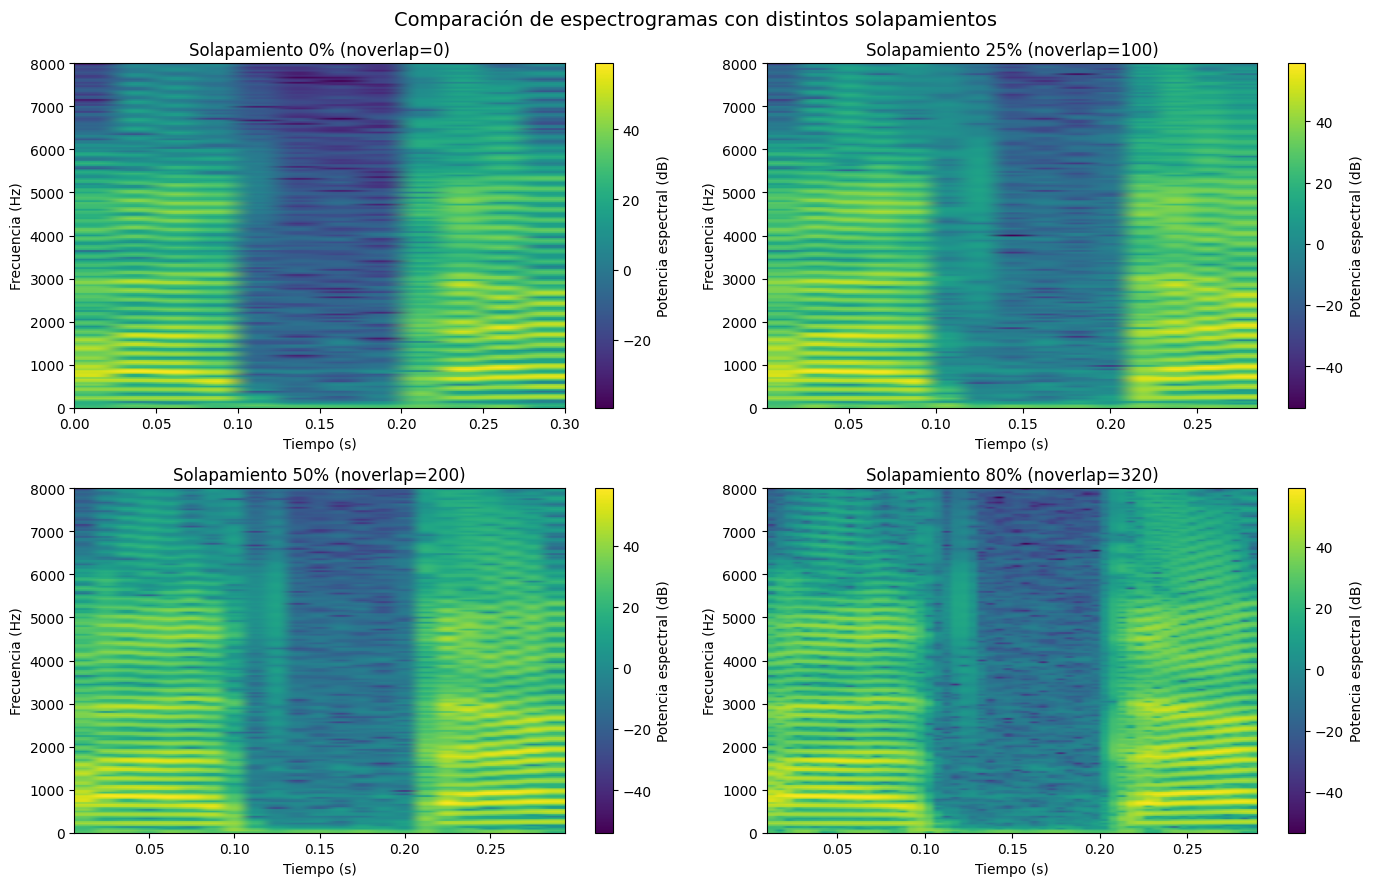

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Parámetros del espectrograma
NFFT = 400  # Ventana de 25 ms si fs = 16000 Hz
solapamientos = [0, 25, 50, 80]

# 2. Obtener información del audio
numero_muestras = len(segmento)
duracion = numero_muestras / fs

print("========== DATOS DEL AUDIO ==========")
print(f"Frecuencia de muestreo (fs): {fs} Hz")
print(f"Número de muestras: {numero_muestras}")
print(f"Duración de segmento: {duracion:.6f} s")
print(f"Duración de segmento: {duracion * 1000:.2f} ms")
print(f"NFFT: {NFFT} muestras")
print(f"Duración de ventana: {NFFT / fs * 1000:.2f} ms")

print("\n====== SOLAPAMIENTOS UTILIZADOS ======")
for porcentaje in solapamientos:
    noverlap = int(NFFT * porcentaje / 100)
    salto = NFFT - noverlap
    print(
        f"Solapamiento: {porcentaje:>2}% | "
        f"noverlap: {noverlap:>3} muestras | "
        f"Salto entre ventanas: {salto:>3} muestras"
    )

# 3. Graficar los cuatro espectrogramas
fig, axs = plt.subplots(2, 2, figsize=(14, 9))
axs = axs.flatten()

for ax, porcentaje in zip(axs, solapamientos):
    noverlap = int(NFFT * porcentaje / 100)

    Pxx, freqs, bins, imagen = ax.specgram(
        segmento,
        NFFT=NFFT,
        Fs=fs,
        noverlap=noverlap,
        scale="dB",
        cmap="viridis"
    )

    ax.set_title(
        f"Solapamiento {porcentaje}% "
        f"(noverlap={noverlap})"
    )
    ax.set_xlabel("Tiempo (s)")
    ax.set_ylabel("Frecuencia (Hz)")
    ax.set_ylim(0, fs / 2)

    fig.colorbar(imagen, ax=ax, label="Potencia espectral (dB)")

fig.suptitle(
    "Comparación de espectrogramas con distintos solapamientos",
    fontsize=14
)
plt.tight_layout()
plt.show()


### Análisis y conclusión del efecto del solapamiento en el espectrograma

Para este análisis se utilizó un segmento de audio de 300 ms, con una frecuencia de muestreo de \(16\,000\ \text{Hz}\) y ventanas de 400 muestras, equivalentes a 25 ms. Se compararon cuatro niveles de solapamiento: 0 %, 25 %, 50 % y 80 %, manteniendo constante el valor de `NFFT`.

En el espectrograma con **0 % de solapamiento**, cada ventana se analiza de manera independiente y no comparte muestras con la siguiente. Al aumentar el solapamiento al 25 % y al 50 %, se obtiene una representación temporal más continua, que permite observar con mayor detalle las variaciones de las componentes frecuenciales del audio. Con un solapamiento del **80 %**, las ventanas avanzan solamente 80 muestras entre análisis consecutivos, lo que genera una mayor cantidad de estimaciones espectrales y permite seguir más detalladamente los cambios temporales de la señal.

En las cuatro gráficas se distinguen regiones de mayor energía, representadas por colores verdes y amarillos, y regiones de menor energía, representadas por colores azules y morados. Estas estructuras frecuenciales se mantienen aproximadamente en las distintas configuraciones, ya que corresponden al mismo segmento de audio. Las diferencias observadas se relacionan principalmente con la cantidad de ventanas analizadas y la continuidad temporal de la representación.

En conclusión, **un mayor solapamiento mejora la continuidad temporal y permite visualizar con más detalle la evolución del contenido frecuencial**, aunque incrementa el costo computacional. Sin embargo, el solapamiento no aumenta por sí mismo la resolución en frecuencia, puesto que esta depende principalmente de la duración de la ventana y del número de puntos utilizados en la transformada. Por tanto, la elección del solapamiento representa un compromiso entre el detalle temporal deseado y el costo de procesamiento.